1. Import Libraries & Load Dataset

In [74]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load dataset
df = pd.read_csv("social_media_engagement_5000.csv")

print("Dataset Loaded Successfully")
df.head()

Dataset Loaded Successfully


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


2. Data Import & Setup

In [75]:
# Shape
print("Rows and Columns:", df.shape)

# Columns
print(df.columns)

# Data types
print(df.dtypes)

# Information
df.info()

Rows and Columns: (5000, 19)
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')
user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-

3.Convert Date Column

In [76]:
df['posted_at'] = pd.to_datetime(df['posted_at'], dayfirst=True)

4.NumPy Operations

In [77]:
likes_array = np.array(df['likes'])

print("Average Likes:", np.nanmean(likes_array))
print("Maximum Likes:", np.nanmax(likes_array))
print("Minimum Likes:", np.nanmin(likes_array))

Average Likes: 10107.043711340206
Maximum Likes: 19998.0
Minimum Likes: 10.0


Task 2: Data Cleaning

Missing Values

2.1 Check missing values

In [78]:
print(df.isnull().sum())

# Alternative
print(df.isna().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


2.2 Filling Missing Values

In [79]:
numeric_cols = ['likes','comments','shares',
                'watch_time_sec',
                'impression_count',
                'follower_count',
                'engagement_rate']

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

categorical_cols = ['gender','country',
                    'post_type','post_category',
                    'sentiment','device_type']

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

2.3 Duplicate Handling

In [80]:
print("Duplicates:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("After Removal:", df.shape)

Duplicates: 0
After Removal: (5000, 19)


C:\Users\HP\AppData\Local\Temp\ipykernel_166688\2960978242.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


2.4 Standardize Categories

In [81]:
df['gender'] = df['gender'].str.strip().str.title()

df['sentiment'] = df['sentiment'].str.strip().str.lower()

df['device_type'] = df['device_type'].str.strip().str.lower()

2.5 Handle Unrealistic Values

In [82]:
df['likes'] = df['likes'].clip(lower=0)
df['comments'] = df['comments'].clip(lower=0)
df['shares'] = df['shares'].clip(lower=0)

2.6 Extract Hashtag Count

In [83]:
df['hashtag_count'] = df['hashtags'].fillna('').apply(
    lambda x: len(str(x).split())
)

2.7 Clean Sentiment Labels

In [84]:
df['sentiment'] = df['sentiment'].replace({
    'Positive':'positive',
    'Negative':'negative',
    'Neutral':'neutral'
})

Task 3: Data Exploration

3.1 Structure

In [85]:
df.head()
df.tail()

print(df.shape)
print(df.columns)


(5000, 20)
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')


3.2 Info & Datatypes

In [86]:
df.info()
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               4850 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

3.3 Summary Statistics

In [87]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,4850.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.912381,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


3.4 Categorical Analysis

In [88]:
print(df['post_type'].value_counts())

print(df['country'].nunique())

print(df['sentiment'].unique())

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
10
<StringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str


3.5 Correlation Matrix

In [89]:
corr_matrix = df.corr(numeric_only=True)

corr_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,is_verified,engagement_rate,hashtag_count
user_id,1.000000,-0.006789,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,0.004058,-0.004282,-0.013692
age,-0.006789,1.000000,-0.013353,-0.036767,-0.007369,0.014120,0.005677,0.013513,-0.025416,-0.000112,0.008044,0.007336
post_id,0.020051,-0.013353,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.025208,0.010139,0.007344
likes,0.025811,-0.036767,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,-0.016200,0.093520,-0.002190
comments,-0.033395,-0.007369,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,-0.012398,0.000051,-0.015230
shares,0.013763,0.014120,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.007025,0.021724,0.013379
watch_time_sec,-0.016847,0.005677,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,0.012326,-0.001148,-0.023301
impression_count,0.015326,0.013513,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,0.008317,-0.232226,-0.002714
follower_count,0.010124,-0.025416,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,-0.017808,0.002292,0.008802
is_verified,0.004058,-0.000112,0.025208,-0.016200,-0.012398,0.007025,0.012326,0.008317,-0.017808,1.000000,0.005528,0.001396


3.6 GroupBy Analysis

Average Likes by Post Type

In [90]:
df.groupby('post_type')['likes'].mean().sort_values(ascending=False)

post_type
video    10188.600000
image    10104.865277
text     10100.148193
reel     10037.802416
Name: likes, dtype: float64

Average Impressions by Country

In [91]:
df.groupby('country')['impression_count'].mean().sort_values(ascending=False)

country
India        52462.386916
France       51727.673387
USA          51263.872255
UK           51119.393509
Japan        49616.135593
Brazil       49193.174603
UAE          48928.413519
Canada       48703.150097
Germany      48605.406122
Australia    48346.383367
Name: impression_count, dtype: float64

Task 4: Data Wrangling


4.1 Create Engagement Score

In [92]:
df['engagement_score'] = (
    df['likes'] +
    df['comments']*2 +
    df['shares']*3
)

4.2 Log Transformation

In [93]:
df['log_likes'] = np.log1p(df['likes'])

4.3 Group By Post Type

In [94]:
post_summary = df.groupby('post_type')[['likes',
                                        'comments',
                                        'shares',
                                        'engagement_rate']].mean()

post_summary

,likes,comments,shares,engagement_rate
post_type,,,,
image,10104.865277,1525.235766,1019.289495,0.895646
reel,10037.802416,1504.187062,982.042089,0.783047
text,10100.148193,1499.106024,1013.989558,1.064549
video,10188.600000,1479.160000,996.834286,1.122365


4.4 Group By Country

In [95]:
country_summary = df.groupby('country')['engagement_rate'].mean()

country_summary.sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

4.5 Group By Sentiment

In [96]:
sentiment_summary = df.groupby('sentiment')[
    ['likes','comments','shares']
].mean()

sentiment_summary

,likes,comments,shares
sentiment,,,
negative,10208.096875,1516.094792,1007.307292
neutral,9923.194499,1528.404060,996.565160
positive,10180.062077,1480.650617,1005.086749


Task 5: Statistical Analysis

In [97]:
columns = ['likes',
           'comments',
           'shares',
           'watch_time_sec',
           'engagement_rate',
           'follower_count']

for col in columns:

    print("\n")
    print("COLUMN:", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])

    print("Std Dev:", df[col].std())
    print("Variance:", df[col].var())

    print("25th Percentile:", df[col].quantile(0.25))
    print("50th Percentile:", df[col].quantile(0.50))
    print("75th Percentile:", df[col].quantile(0.75))

    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())



COLUMN: likes
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5
Std Dev: 5702.293017183877
Variance: 32516145.65382401
25th Percentile: 5235.0
50th Percentile: 10105.5
75th Percentile: 14959.0
Skewness: -0.006893616532184353
Kurtosis: -1.1499923609078413


COLUMN: comments
Mean: 1502.0398
Median: 1497.0
Mode: 1497.0
Std Dev: 856.3933120458984
Variance: 733409.5049169434
25th Percentile: 792.0
50th Percentile: 1497.0
75th Percentile: 2235.25
Skewness: 0.0038017289479836
Kurtosis: -1.1443748352968999


COLUMN: shares
Mean: 1002.9106
Median: 1012.0
Mode: 1012.0
Std Dev: 570.8551999758852
Variance: 325875.65933950787
25th Percentile: 511.0
50th Percentile: 1012.0
75th Percentile: 1483.0
Skewness: -0.014653583910311055
Kurtosis: -1.1468565626589917


COLUMN: watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916
Std Dev: 2308.0964590420845
Variance: 5327309.264242608
25th Percentile: 2017.75
50th Percentile: 4034.5
75th Percentile: 6020.25
Skewness: -0.018196273193232235
Kurtosis: -1.195651

Task 6: Visualization (More Than 8 Plots)

1. Scatter Plot

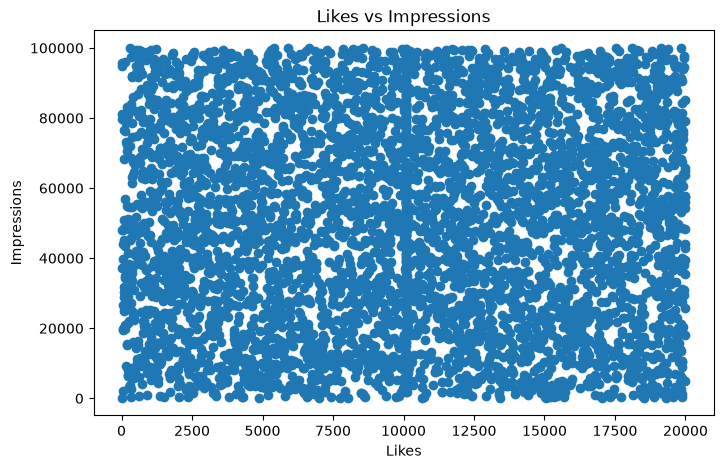

In [98]:
plt.figure(figsize=(8,5))
plt.scatter(df['likes'], df['impression_count'])
plt.title("Likes vs Impressions")
plt.xlabel("Likes")
plt.ylabel("Impressions")
plt.show()

2. Line Plot Daily Engagement Trend

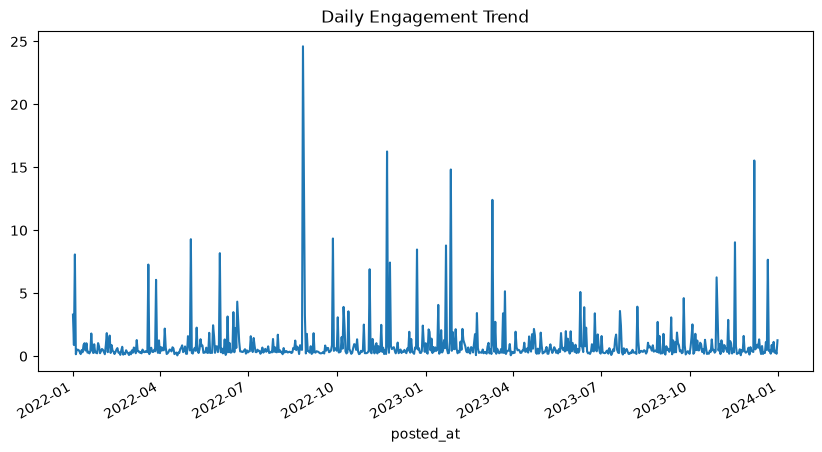

In [99]:
daily = df.groupby('posted_at')['engagement_rate'].mean()

plt.figure(figsize=(10,5))
daily.plot()
plt.title("Daily Engagement Trend")
plt.show()

3. Bar Chart Posts by Category

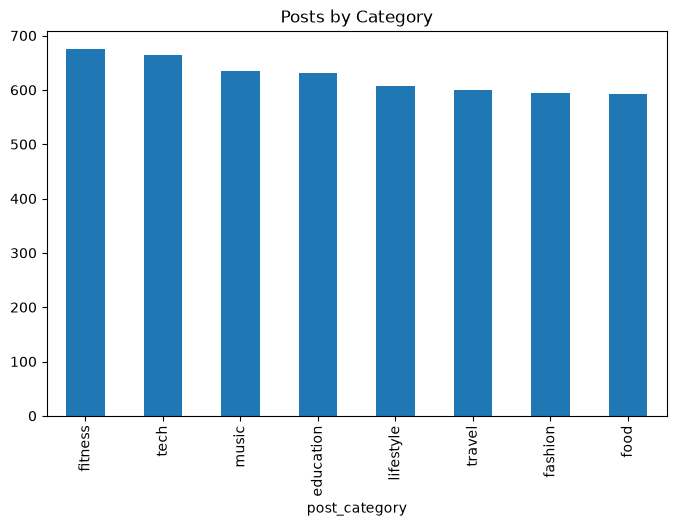

In [100]:
df['post_category'].value_counts().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Posts by Category")
plt.show()

4. Pie Chart Gender Distribution

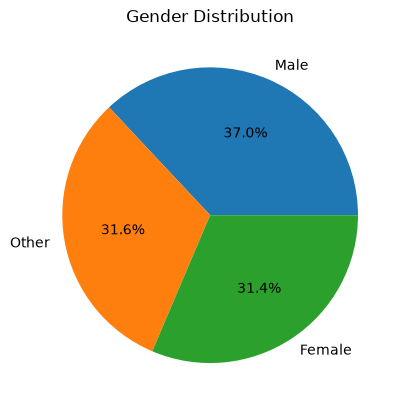

In [101]:
df['gender'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title("Gender Distribution")
plt.ylabel("")
plt.show()

5. Histogram Age

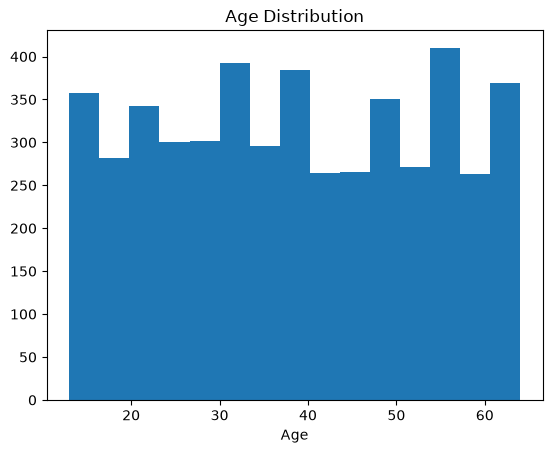

In [102]:
plt.hist(df['age'], bins=15)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()

6. Box Plot Engagement Rate

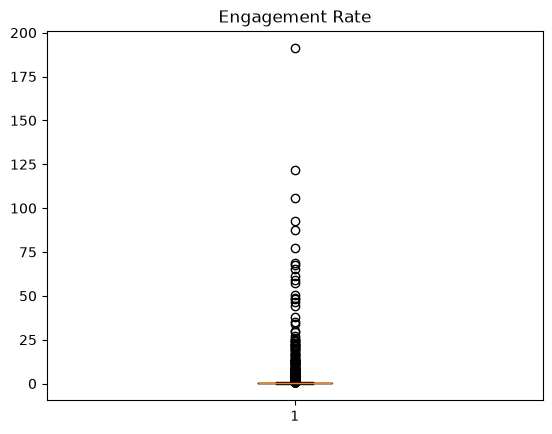

In [103]:
plt.boxplot(df['engagement_rate'])

plt.title("Engagement Rate")
plt.show()

7. Count Plot Post Type

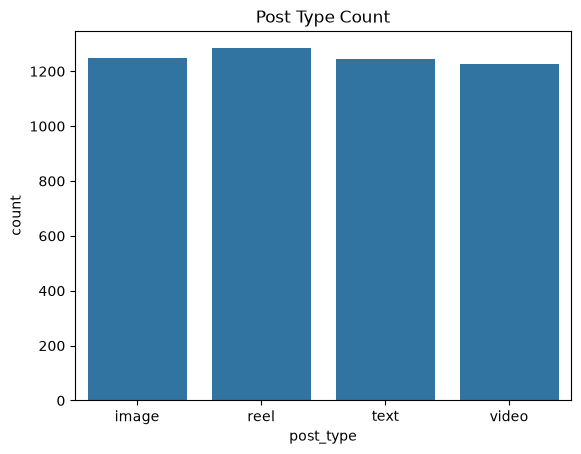

In [104]:
sns.countplot(data=df, x='post_type')

plt.title("Post Type Count")
plt.show()

8. Bar Plot Average Likes by Category

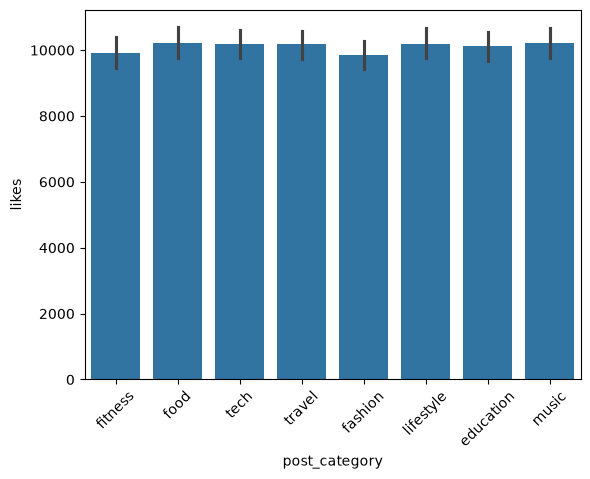

In [105]:
sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    estimator=np.mean
)

plt.xticks(rotation=45)
plt.show()

9. Violin Plot Followers vs Sentiment

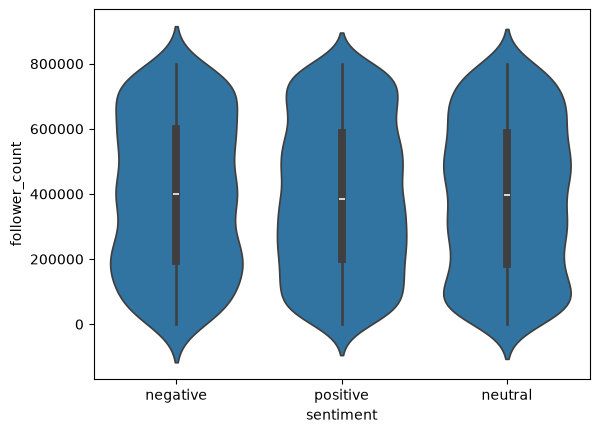

In [106]:
sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.show()

10. Pair Plot

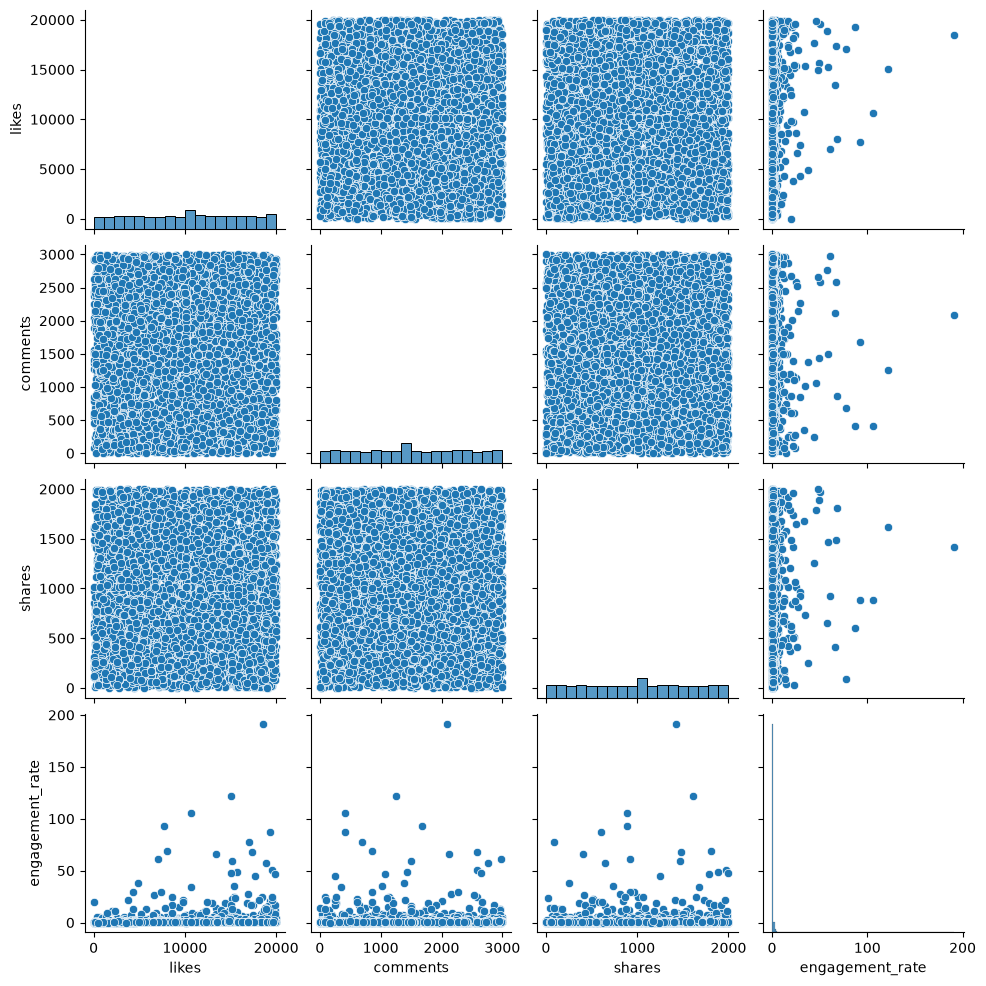

In [107]:
sns.pairplot(
    df[['likes',
        'comments',
        'shares',
        'engagement_rate']]
)

plt.show()

11. Heatmap

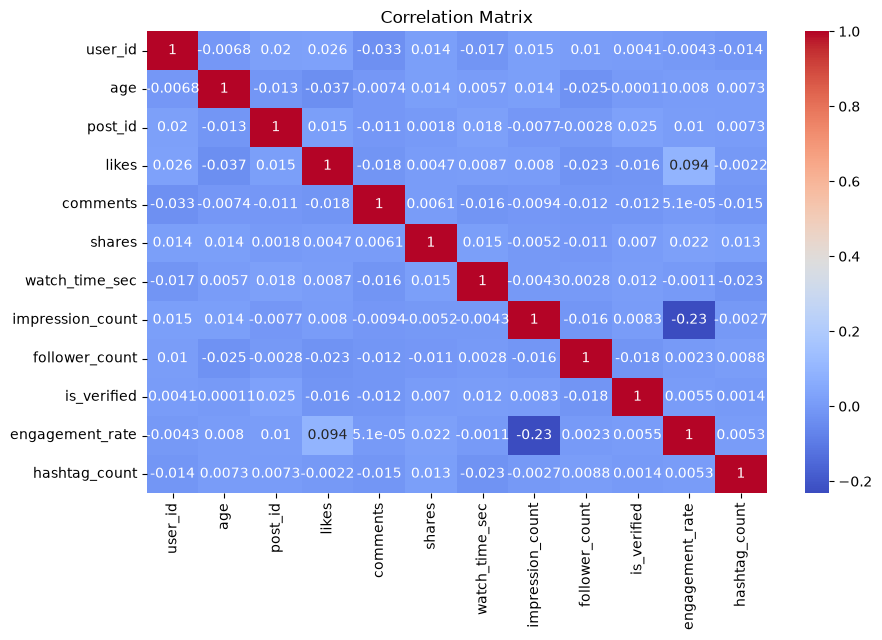

In [108]:
plt.figure(figsize=(10,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()

12. Swarm Plot

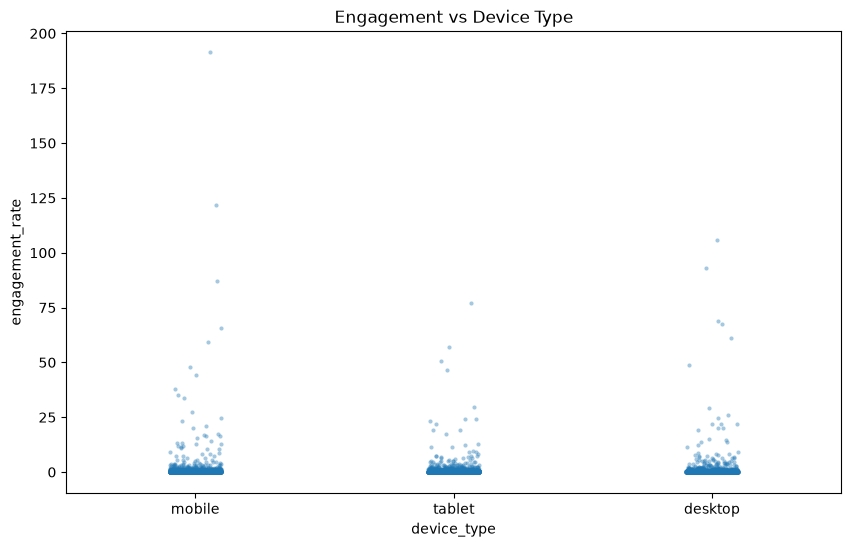

In [109]:
plt.figure(figsize=(10,6))

sns.stripplot(
    data=df,
    x='device_type',
    y='engagement_rate',
    jitter=True,
    alpha=0.4,
    size=3
)

plt.title("Engagement vs Device Type")
plt.show()

13. Plotly Interactive Chart

In [110]:
fig = px.scatter(
    df,
    x='likes',
    y='engagement_rate',
    color='post_type',
    title='Interactive Engagement Analysis'
)

fig.show()

Final Insights Section

Highest Engagement Post Type

In [111]:
df.groupby('post_type')['engagement_rate'].mean()\
.sort_values(ascending=False)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

Best Performing Category

In [112]:
df.groupby('post_category')['engagement_rate'].mean()\
.sort_values(ascending=False)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

Countries with Highest Engagement

In [113]:
df.groupby('country')['engagement_rate'].mean()\
.sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

Age vs Engagement

In [114]:
df.groupby('age')['engagement_rate'].mean()

age
13.0    0.455583
14.0    1.003067
15.0    0.714170
16.0    1.226848
17.0    0.858763
18.0    0.888391
19.0    0.676687
20.0    0.515541
21.0    0.452752
22.0    0.586786
23.0    0.922448
24.0    2.897327
25.0    1.041681
26.0    0.501467
27.0    0.775328
28.0    0.385081
29.0    1.110432
30.0    1.270129
31.0    0.440684
32.0    0.581710
33.0    1.277557
34.0    0.557236
35.0    1.521596
36.0    0.609569
37.0    0.494109
38.0    1.247501
39.0    0.436184
40.0    0.930504
41.0    1.540070
42.0    1.350772
43.0    0.566439
44.0    0.795102
45.0    0.513521
46.0    0.663994
47.0    1.402015
48.0    1.675878
49.0    0.999235
50.0    1.552627
51.0    2.397295
52.0    0.867426
53.0    0.707924
54.0    1.002622
55.0    2.599106
56.0    0.524008
57.0    0.919751
58.0    0.435130
59.0    0.495578
60.0    0.759586
61.0    0.553854
62.0    1.005127
63.0    1.303909
64.0    0.402533
Name: engagement_rate, dtype: float64

Verified vs Non-Verified Accounts

In [115]:
df.groupby('is_verified')['engagement_rate'].mean()

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64

Best Time for Impressions

In [116]:
df['hour'] = df['posted_at'].dt.hour

df.groupby('hour')['impression_count'].mean()\
.sort_values(ascending=False)

hour
0    50013.7328
Name: impression_count, dtype: float64

Device Impact on Watch Time

In [117]:
df.groupby('device_type')['watch_time_sec'].mean()

device_type
desktop    3974.792521
mobile     4087.830760
tablet     3979.736429
Name: watch_time_sec, dtype: float64

Best Performing Sentiment

In [118]:
df.groupby('sentiment')['engagement_rate'].mean()

sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64